**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**24 | Multi-Seed Stability and Class-Imbalance Loss Ablation**

![Stage 24 scientific workflow](../images/24_workflow.svg)

**Objective:** Assess the sensitivity of shortlisted HARTH temporal models to initialisation seed and compare class-aware loss functions under matched Development conditions.

**Dataset:** The 29-participant HARTH v2.0 Development cohort from Notebook 23, using the same 14,201 source windows, eight documented activity classes and three participant-disjoint folds.

**Notebook Scope:** Evaluate ResNet and TCN with three predeclared seeds, then compare weighted Cross-Entropy, Focal Loss and Class-Balanced Cross-Entropy for ResNet. The 36 unique fold-specific jobs use Development data only; reserved Test recordings S023 and S032 are not loaded. Differences remain exploratory rather than proof of model superiority.

**01. Define Robustness and Loss-Ablation Experiments**

Notebook 23 recorded mean Development Macro F1 of 0.8328 for 1D-ResNet, 0.8138 for TCN and 0.8094 for Random Forest. Random Forest had higher pooled Shuffling F1 (0.5032) than ResNet (0.3962) and TCN (0.3392).

The multi-seed comparison uses ResNet and TCN with weighted Cross-Entropy under seeds `42`, `123` and `2026`. The ResNet loss ablation adds Focal Loss (gamma 2) and Class-Balanced Cross-Entropy (beta 0.9999). Shared weighted-loss runs are not duplicated.

In [2]:
# ================ 01. Research Environment and GPU Validation ================

# ----------- 1. Resolve the repository and configure import paths ------------
#   research tools.
# ------------------ 2. Import Python standard-library tools ------------------
import sys
from pathlib import Path
# ---------------- 3. Import analysis and evaluation utilities ----------------
import numpy as np
import pandas as pd
# --------------- 4. Import plotting and notebook display tools ---------------
import matplotlib.pyplot as plt
# -------------- 5. Import deep-learning and training utilities ---------------
import torch
# ---------------- 6. Configure notebook plotting and display -----------------
from IPython.display import display
root=Path.cwd().resolve()
while not (root/"code/python/src/core/data_loading.py").is_file():
    if root==root.parent: raise RuntimeError("Run inside the HMI repository.")
    root=root.parent
sys.path.insert(0,str(root/"code/python/src"))
sys.path.insert(0,str(root/"studies/wearable_activity_recognition/src"))
# -------------------- 7. Import local research utilities ---------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, prepare_harth_window_cohort
from core.temporal_benchmark import make_benchmark_plan
from core.robustness_experiments import (
    ROBUST_MODELS, LOSS_METHODS, run_robustness_job,
    summarise_robustness_results, calculate_loss_weights
)

# ----------- 8. Require CUDA and full-precision model computations -----------
#   23.
if not torch.cuda.is_available():
    raise RuntimeError("Enable Colab GPU in Runtime > Change runtime type.")
torch.set_float32_matmul_precision("highest")
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
DEVICE="cuda"
SEEDS=(42,123,2026)
CLASSES=tuple(range(1,9))
RESERVED_TEST={"S023","S032"}
DEVELOPMENT=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CACHE_DIR=root/"data/processed/harth_stage24_robustness"
MAX_STEPS=400
assert len(DEVELOPMENT)==29 and len(SEEDS)==3

# ------------ 9. Report environment and fixed experiment settings ------------
#   controls.
print(""+"="*70)
print("STAGE 24 | MULTI-SEED AND LOSS ROBUSTNESS")
print("="*70)
print("GPU:",torch.cuda.get_device_name(0))
print("PyTorch:",torch.__version__,"| CUDA:",torch.version.cuda)
print("Seeds:",SEEDS,"| Group folds: 3 | Updates per job:",MAX_STEPS)
print("Protected source subjects:",sorted(RESERVED_TEST))
print("="*70)

STAGE 24 | MULTI-SEED AND LOSS ROBUSTNESS
GPU: Tesla T4
PyTorch: 2.11.0+cu128 | CUDA: 12.8
Seeds: (42, 123, 2026) | Group folds: 3 | Updates per job: 400
Protected source subjects: ['S023', 'S032']


**02. Reconstruct the Matched Source-Window Cohort**

Use the pinned HARTH v2.0 recording revision and the existing 500-window-per-participant protocol: 100-sample windows, 50-sample stride, label purity and timestamp-continuity checks. Out-of-task codes are excluded after segmentation. The source fingerprint and three participant-disjoint folds must match Notebook 23.

In [3]:
# ====================== 02. Matched HARTH Source Cohort ======================

# ---------- 1. Prepare source-aligned eight-class activity windows -----------
#   original Test.
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT,data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=500,
    window_size=100,step_size=50,sampling_rate=50,
)
assert X.shape==(14201,6,100)
assert not(set(metadata["subject_id"])&RESERVED_TEST)

# --------------- 2. Reuse the three participant-disjoint folds ---------------
#   held-out folds.
plan=make_benchmark_plan(X,y,metadata["subject_id"].to_numpy(),
                         CLASSES,n_splits=3,forbidden_subjects=RESERVED_TEST)
print("Development source SHA256:",plan["fingerprint"])
display(overview[["subject_id","eligible_windows","sampled_windows"]])
assert len(plan["folds"])==3

Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Development source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Predeclare Unique Model, Loss and Seed Conditions**

The grid contains 12 unique model/loss/seed combinations: six weighted-Cross-Entropy conditions for ResNet and TCN, and six additional ResNet Focal/Class-Balanced conditions. Across three folds this produces 36 model fits. Each run starts with fresh weights, uses fold Train-only scaling and loss weighting, and reports predictions after 400 optimiser updates.

Random Forest results from Notebook 23 serve as a historical reference, not a new multi-seed RF experiment.

In [4]:
# ================= 03. Predeclared Seed and Loss Conditions ==================

# ----------- 1. Reuse weighted-loss runs across experiment groups ------------
#   duplicate its jobs.
EXPERIMENTS=[
    (model,"weighted_ce",seed)
    for model in ("1D-ResNet","TCN") for seed in SEEDS
]+[
    ("1D-ResNet",loss,seed)
    for loss in ("focal","class_balanced") for seed in SEEDS
]
assert len(EXPERIMENTS)==12 and len(set(EXPERIMENTS))==12
job_grid=pd.DataFrame([
    {"architecture":arch,"loss":loss,"seed":seed,"fold":fold}
    for arch,loss,seed in EXPERIMENTS for fold,_,_ in plan["folds"]
])
display(job_grid)
print("Distinct conditions:",len(EXPERIMENTS))
print("Unique model/fold training jobs:",len(job_grid))

# ------ 2. Record all preselected fixed-batch training hyperparameters. ------
conditions=pd.DataFrame([
    {"setting":"Train source-window cap","value":500},
    {"setting":"Optimizer updates","value":MAX_STEPS},
    {"setting":"Batch size","value":128},
    {"setting":"Learning rate","value":0.001},
    {"setting":"Focal gamma","value":2.0},
    {"setting":"Class-balanced beta","value":0.9999},
    {"setting":"Primary metric","value":"Fixed 8-class Macro F1"},
])
display(conditions)

,architecture,loss,seed,fold
0,1D-ResNet,weighted_ce,42,1
1,1D-ResNet,weighted_ce,42,2
2,1D-ResNet,weighted_ce,42,3
3,1D-ResNet,weighted_ce,123,1
4,1D-ResNet,weighted_ce,123,2
5,1D-ResNet,weighted_ce,123,3
6,1D-ResNet,weighted_ce,2026,1
7,1D-ResNet,weighted_ce,2026,2
8,1D-ResNet,weighted_ce,2026,3
9,TCN,weighted_ce,42,1


Distinct conditions: 12
Unique model/fold training jobs: 36


,setting,value
0,Train source-window cap,500
1,Optimizer updates,400
2,Batch size,128
3,Learning rate,0.001
4,Focal gamma,2.0
5,Class-balanced beta,0.9999
6,Primary metric,Fixed 8-class Macro F1


**04. Define Class-Weighted and Focal Losses**

Weighted Cross-Entropy uses inverse-square-root weights from fold Train labels. Focal Loss applies the factor `(1-p_true)^gamma` and the same Train-derived class weights, normalising by their sum within each mini-batch. Class-Balanced Cross-Entropy instead uses effective-number weighting with the fixed beta. These alternatives change optimisation behaviour and do not guarantee improvements for rare activities.

In [5]:
# ================ 04. Training-Only Class Weight Comparisons =================

# ----------- 1. Illustrate class weighting using fold Train labels -----------
#   loss-weight tables.
_,first_train,first_validation=plan["folds"][0]
count_train=pd.Series(y[first_train]).value_counts().reindex(CLASSES,fill_value=0)
loss_weights=pd.DataFrame({
    "class_code":CLASSES,
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "train_windows":count_train.to_numpy(),
})
for mode in LOSS_METHODS:
    loss_weights[mode]=calculate_loss_weights(y[first_train],CLASSES,method=mode)
display(loss_weights.round(4))

# ------------ 2. Exclude held-out participants from class weights ------------
#   weights.
assert not(set(plan["groups"][first_train])&set(plan["groups"][first_validation]))
print("Loss-weight calibration source: FOLD TRAIN ONLY")

,class_code,activity,train_windows,weighted_ce,focal,class_balanced
0,1,Walking,2068,0.4560,0.4560,0.1700
1,2,Running,799,0.7336,0.7336,0.4136
2,3,Shuffling,168,1.6000,1.6000,1.9066
3,4,Stairs ascending,135,1.7848,1.7848,2.3687
4,5,Stairs descending,136,1.7782,1.7782,2.3514
5,6,Standing,1621,0.5151,0.5151,0.2123
6,7,Sitting,3577,0.3467,0.3467,0.1056
7,8,Lying,697,0.7855,0.7855,0.4718


Loss-weight calibration source: FOLD TRAIN ONLY


**05. Run and Verify 36 GPU Jobs**

Run each unique architecture, loss, seed and fold condition once. Save source-row IDs, actual labels, predictions, metrics, runtime and configuration fingerprints only after successful completion. Compatible cached jobs may be reused when their underlying files remain available; incomplete or mismatched evidence must be rejected.

In [6]:
# ================== 05. Matched Multi-Seed GPU Experiments ===================

# ---------- 1. Run matched conditions on held-out Development folds ----------
#   partitions.
jobs=[]
for architecture,loss,seed in EXPERIMENTS:
    print("\n"+"="*70)
    print(f"MODEL: {architecture} | LOSS: {loss} | SEED: {seed}")
    print("="*70)
    for fold,train_rows,validation_rows in plan["folds"]:
        result=run_robustness_job(
            plan,architecture,fold,seed,loss,CACHE_DIR,
            device=DEVICE,max_steps=MAX_STEPS,
            batch_size=128,learning_rate=1e-3,
            focal_gamma=2.0,beta=0.9999,
        )
        jobs.append(result)

# ------- 2. Refuse to report partial trials as a complete experiment. --------
assert len(jobs)==len(job_grid)==36
print("\n"+"="*70)
print("ALL 36 MATCHED DEVELOPMENT ROBUSTNESS JOBS FINISHED")
print("Cache location:",CACHE_DIR)
print("="*70)


MODEL: 1D-ResNet | LOSS: weighted_ce | SEED: 42
RUNNING: 1D-ResNet | weighted_ce | seed=42 | fold=1
  1D-ResNet | weighted_ce | seed 42 | Fold 1: 100/400, Train loss=0.5261
  1D-ResNet | weighted_ce | seed 42 | Fold 1: 200/400, Train loss=0.2852
  1D-ResNet | weighted_ce | seed 42 | Fold 1: 300/400, Train loss=0.0903
  1D-ResNet | weighted_ce | seed 42 | Fold 1: 400/400, Train loss=0.1557
COMPLETED: 1D-ResNet | weighted_ce | seed 42 | fold 1 | Macro F1=0.7879
RUNNING: 1D-ResNet | weighted_ce | seed=42 | fold=2
  1D-ResNet | weighted_ce | seed 42 | Fold 2: 100/400, Train loss=0.2496
  1D-ResNet | weighted_ce | seed 42 | Fold 2: 200/400, Train loss=0.2776
  1D-ResNet | weighted_ce | seed 42 | Fold 2: 300/400, Train loss=1.0048
  1D-ResNet | weighted_ce | seed 42 | Fold 2: 400/400, Train loss=0.0410
COMPLETED: 1D-ResNet | weighted_ce | seed 42 | fold 2 | Macro F1=0.8360
RUNNING: 1D-ResNet | weighted_ce | seed=42 | fold=3
  1D-ResNet | weighted_ce | seed 42 | Fold 3: 100/400, Train loss=0

**06. Reconstruct Complete Out-of-Fold Evidence**

For each of the 12 conditions, verify exactly one held-out prediction per selected Development window across three folds. Calculate fold metrics, fixed eight-class participant-level Macro F1 and pooled class-level precision, recall, F1 and support. Overlapping windows remain correlated within participants.

In [7]:
# ================ 06. Complete Held-Out Evidence and Metrics =================

# ----------- 1. Recalculate metrics from verified prediction rows ------------
#   pairs.
fold_results,subject_results,class_results,predictions=(
    summarise_robustness_results(plan,jobs,EXPERIMENTS)
)
assert len(fold_results)==36
display(fold_results[[
    "architecture","loss_method","seed","fold","macro_f1",
    "balanced_accuracy","train_seconds","validation_windows"
]].round(4))

# ------ 2. Show independent participant and fixed-task class coverage. -------
assert len(subject_results)==29*len(EXPERIMENTS)
assert len(class_results)==len(CLASSES)*len(EXPERIMENTS)
print("Unique development participants:",subject_results["subject_id"].nunique())
print("True held-out source rows per condition:",len(y))

,architecture,loss_method,seed,fold,macro_f1,balanced_accuracy,train_seconds,validation_windows
0,1D-ResNet,weighted_ce,42,1,0.7879,0.8710,13.9445,5000
1,1D-ResNet,weighted_ce,42,2,0.8360,0.8780,10.6531,4701
2,1D-ResNet,weighted_ce,42,3,0.8747,0.8576,10.6864,4500
3,1D-ResNet,weighted_ce,123,1,0.7966,0.8822,10.7293,5000
4,1D-ResNet,weighted_ce,123,2,0.8219,0.8693,10.6784,4701
5,1D-ResNet,weighted_ce,123,3,0.8723,0.8654,10.7475,4500
6,1D-ResNet,weighted_ce,2026,1,0.8260,0.8715,10.7843,5000
7,1D-ResNet,weighted_ce,2026,2,0.7799,0.8631,10.7084,4701
8,1D-ResNet,weighted_ce,2026,3,0.8625,0.8432,10.7932,4500
9,TCN,weighted_ce,42,1,0.7634,0.8548,3.4548,5000


Unique development participants: 29
True held-out source rows per condition: 14201


**07. Compare ResNet and TCN Across Seeds**

Hold the weighted-Cross-Entropy formulation constant and report all three seeds and their fixed folds, rather than selecting the best run. Across-seed means and variation describe initialisation sensitivity; three seeds do not define a population confidence interval or independent replication.

architecture  1D-ResNet     TCN
seed fold                      
42   1           0.7879  0.7634
     2           0.8360  0.7898
     3           0.8747  0.8883
123  1           0.7966  0.7876
     2           0.8219  0.7554
     3           0.8723  0.8616
2026 1           0.8260  0.8167
     2           0.7799  0.7487
     3           0.8625  0.8831

,architecture,seed,mean_macro_f1,fold_sd
0,1D-ResNet,42,0.8328,0.0435
1,1D-ResNet,123,0.8303,0.0386
2,1D-ResNet,2026,0.8228,0.0414
3,TCN,42,0.8138,0.0658
4,TCN,123,0.8015,0.0544
5,TCN,2026,0.8162,0.0672


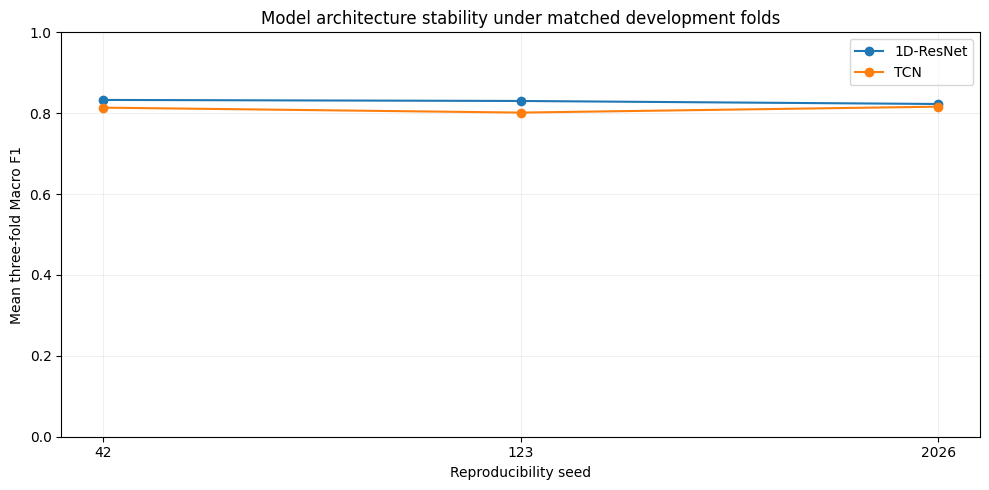

In [8]:
# ==================== 07. Paired Fold and Seed Stability =====================

# ----------- 1. Compare ResNet and TCN under matched weighted loss -----------
#   weighted CE loss.
stability=fold_results.loc[fold_results["loss_method"]=="weighted_ce"]
display(stability.pivot_table(
    index=["seed","fold"],columns="architecture",values="macro_f1"
).round(4))
seed_summary=stability.groupby(["architecture","seed"],as_index=False).agg(
    mean_macro_f1=("macro_f1","mean"),
    fold_sd=("macro_f1","std"),
)
display(seed_summary.round(4))

# ------------- 2. Visualise score variation across matched seeds -------------
#   axis scaling.
fig,ax=plt.subplots(figsize=(10,5))
for arch,frame in seed_summary.groupby("architecture"):
    ax.plot(frame["seed"].astype(str),frame["mean_macro_f1"],marker="o",label=arch)
ax.set(xlabel="Reproducibility seed",ylabel="Mean three-fold Macro F1",
       title="Model architecture stability under matched development folds",ylim=(0,1))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

**08. Compare ResNet Loss Functions**

Compare weighted Cross-Entropy, Focal Loss and Class-Balanced Cross-Entropy at matched seed, fold, source rows, architecture and update budget. Assess the full distribution of Development scores, not just the most favourable seed or fold. These tests measure loss-formulation differences within the fixed pipeline.

loss_method  class_balanced   focal  weighted_ce
seed fold                                       
42   1               0.7471  0.7687       0.7879
     2               0.7699  0.7807       0.8360
     3               0.8725  0.8681       0.8747
123  1               0.7823  0.7385       0.7966
     2               0.8030  0.8229       0.8219
     3               0.8376  0.8720       0.8723
2026 1               0.7624  0.8043       0.8260
     2               0.6843  0.7833       0.7799
     3               0.8644  0.8139       0.8625

loss_method  focal_minus_weighted  class_balanced_minus_weighted
seed fold                                                       
42   1                    -0.0192                        -0.0408
     2                    -0.0552                        -0.0660
     3                    -0.0066                        -0.0022
123  1                    -0.0581                        -0.0142
     2                     0.0010                        -0.0190
     3                    -0.0003                        -0.0347
2026 1                    -0.0217                        -0.0636
     2                     0.0035                        -0.0955
     3                    -0.0486                         0.0019

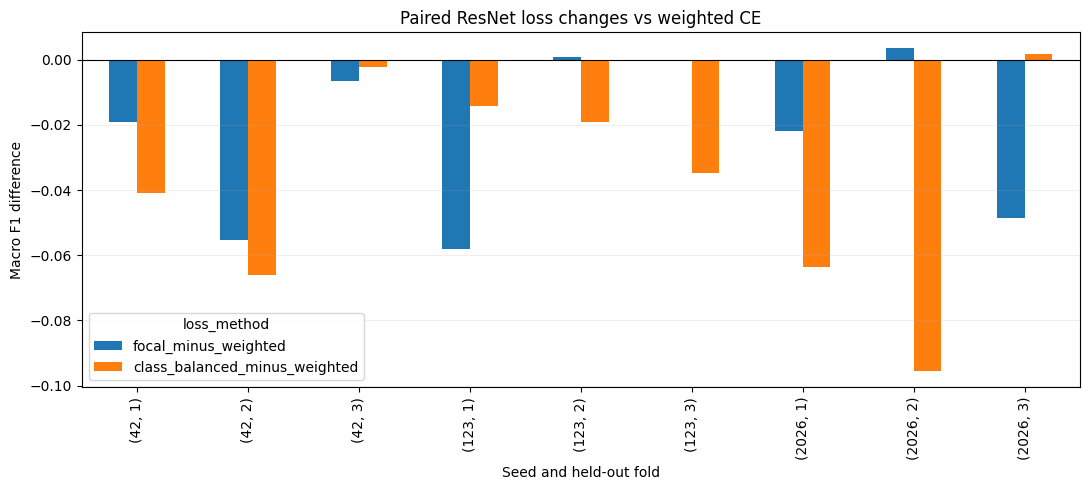

In [9]:
# ====================== 08. Paired ResNet Loss Ablation ======================

# ------- 1. Compare loss functions over identical seed-by-fold blocks. -------
resnet=fold_results[fold_results["architecture"]=="1D-ResNet"]
paired_loss=resnet.pivot(index=["seed","fold"],columns="loss_method",values="macro_f1")
display(paired_loss.round(4))
paired_loss["focal_minus_weighted"]=paired_loss["focal"]-paired_loss["weighted_ce"]
paired_loss["class_balanced_minus_weighted"]=(
    paired_loss["class_balanced"]-paired_loss["weighted_ce"]
)
display(paired_loss[[
    "focal_minus_weighted","class_balanced_minus_weighted"
]].round(4))

# -------- 2. Plot paired loss differences without significance claims --------
#   overclaiming.
fig,ax=plt.subplots(figsize=(11,5))
paired_loss[[
    "focal_minus_weighted","class_balanced_minus_weighted"
]].plot(kind="bar",ax=ax)
ax.axhline(0,color="black",linewidth=.8)
ax.set(title="Paired ResNet loss changes vs weighted CE",
       xlabel="Seed and held-out fold",ylabel="Macro F1 difference")
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
plt.show()

**09. Inspect Shuffling and Stair-Class Outcomes**

Report pooled precision, recall, F1 and true support for Shuffling, Stairs ascending and Stairs descending under every model/loss/seed condition. Higher recall may come with lower precision or a cost to other classes; document such trade-offs directly.

,architecture,loss_method,seed,activity,support,precision,recall,f1
2,1D-ResNet,weighted_ce,42,Shuffling,219,0.3422,0.4703,0.3962
3,1D-ResNet,weighted_ce,42,Stairs ascending,192,0.5375,0.8594,0.6613
4,1D-ResNet,weighted_ce,42,Stairs descending,182,0.6946,0.7747,0.7325
10,1D-ResNet,weighted_ce,123,Shuffling,219,0.2759,0.5708,0.3720
11,1D-ResNet,weighted_ce,123,Stairs ascending,192,0.5461,0.8021,0.6498
12,1D-ResNet,weighted_ce,123,Stairs descending,182,0.7172,0.7802,0.7474
18,1D-ResNet,weighted_ce,2026,Shuffling,219,0.2937,0.5982,0.3940
19,1D-ResNet,weighted_ce,2026,Stairs ascending,192,0.4814,0.8750,0.6211
20,1D-ResNet,weighted_ce,2026,Stairs descending,182,0.7683,0.6923,0.7283
26,TCN,weighted_ce,42,Shuffling,219,0.2959,0.3973,0.3392


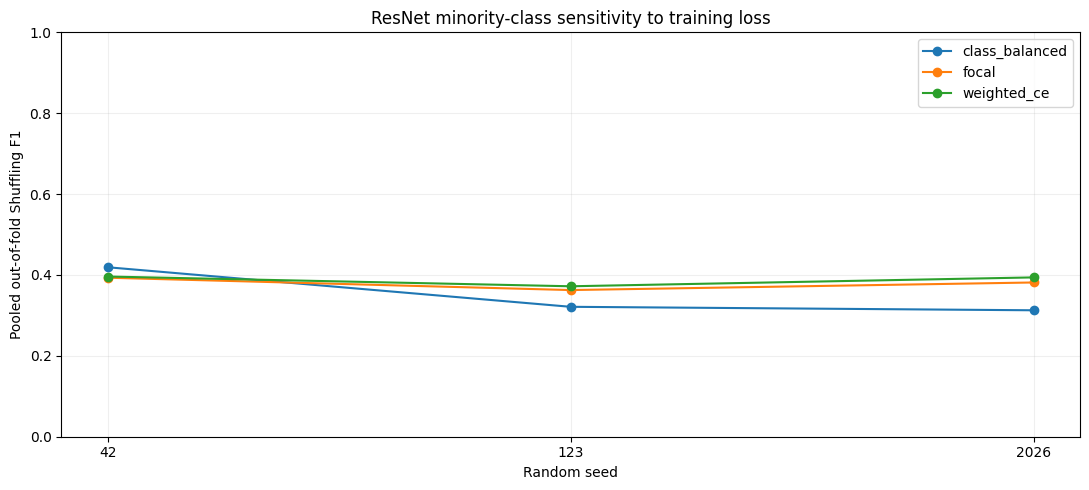

In [10]:
# ================== 09. Minority-Class Outcomes and Support ==================

# ------------ 1. Retain Shuffling and both stair activity classes ------------
#   separate.
minority=class_results.loc[class_results["class_code"].isin([3,4,5])].copy()
minority["activity"]=minority["class_code"].map(ACTIVITY_NAMES)
display(minority[[
    "architecture","loss_method","seed","activity",
    "support","precision","recall","f1"
]].round(4))

# ----------- 2. Compare Shuffling across the ResNet loss variants ------------
#   conditions.
shuffle=minority.loc[
    (minority["architecture"]=="1D-ResNet") & (minority["class_code"]==3)
]
fig,ax=plt.subplots(figsize=(11,5))
for method,frame in shuffle.groupby("loss_method"):
    ax.plot(frame["seed"].astype(str),frame["f1"],marker="o",label=method)
ax.set(xlabel="Random seed",ylabel="Pooled out-of-fold Shuffling F1",
       title="ResNet minority-class sensitivity to training loss",ylim=(0,1))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

**10. Examine Participant-Level Results and Training Cost**

Summarise one fixed eight-class Macro F1 per held-out participant alongside fold and window-level metrics. Record actual model-fit runtime separately from cached restoration. GPU timing is hardware-dependent and is not a direct measure of algorithmic complexity.

In [ ]:
# ==================== 10. Person-Wise Robustness and Cost ====================

# ------------- 1. Summarise participant-level Development scores -------------
#   
people_summary=subject_results.groupby(
    ["architecture","loss_method","seed"],as_index=False
).agg(
    mean_person_macro_f1=("macro_f1_fixed_task","mean"),
    person_macro_f1_sd=("macro_f1_fixed_task","std")
)
display(people_summary.round(4))

# ---------- 2. Compare training time and fold-level score variation ----------
compute=fold_results.groupby(
    ["architecture","loss_method","seed"],as_index=False
).agg(
    mean_fold_macro_f1=("macro_f1","mean"),
    fold_macro_f1_sd=("macro_f1","std"),
    total_train_s=("train_seconds","sum"),
    total_inference_s=("inference_seconds","sum"),
)
display(compute.round(3))

,architecture,loss_method,seed,mean_person_macro_f1,person_macro_f1_sd
0,1D-ResNet,class_balanced,42,0.7058,0.1754
1,1D-ResNet,class_balanced,123,0.6889,0.1471
2,1D-ResNet,class_balanced,2026,0.6720,0.1883
3,1D-ResNet,focal,42,0.7079,0.1588
4,1D-ResNet,focal,123,0.7022,0.1414
5,1D-ResNet,focal,2026,0.7103,0.1657
6,1D-ResNet,weighted_ce,42,0.7311,0.1504
7,1D-ResNet,weighted_ce,123,0.7110,0.1563
8,1D-ResNet,weighted_ce,2026,0.7153,0.1579
9,TCN,weighted_ce,42,0.7059,0.1630


,architecture,loss_method,seed,mean_fold_macro_f1,fold_macro_f1_sd,total_train_s,total_inference_s
0,1D-ResNet,class_balanced,42,0.797,0.067,33.028,0.118
1,1D-ResNet,class_balanced,123,0.808,0.028,33.173,0.125
2,1D-ResNet,class_balanced,2026,0.770,0.090,33.343,0.123
3,1D-ResNet,focal,42,0.806,0.054,33.426,0.123
4,1D-ResNet,focal,123,0.811,0.068,33.195,0.118
5,1D-ResNet,focal,2026,0.801,0.016,33.357,0.117
6,1D-ResNet,weighted_ce,42,0.833,0.043,35.284,0.332
7,1D-ResNet,weighted_ce,123,0.830,0.039,32.155,0.110
8,1D-ResNet,weighted_ce,2026,0.823,0.041,32.286,0.115
9,TCN,weighted_ce,42,0.814,0.066,9.322,0.121


**11. Interpret Robustness Evidence for Model Selection**

Use the repeated-seed Development results to inform the protocol decision in Notebook 25 without treating the selected model's Development score as independent final performance. Consider minority-class precision and recall, class support, cross-seed stability and training cost. Class-balanced weights use correlated windows as count observations, which limits a direct interpretation of their effective-number assumptions.

In [12]:
# ================== 11. Evidence-Bounded Robustness Summary ==================

# -------- 1. Report all predefined conditions without selection bias ---------
#   favourable seeds.
final_summary=compute.groupby(
    ["architecture","loss_method"],as_index=False
).agg(
    mean_across_seed_fold_macro_f1=("mean_fold_macro_f1","mean"),
    across_seed_sd=("mean_fold_macro_f1","std"),
    total_training_s=("total_train_s","sum"),
)
display(final_summary.sort_values(
    "mean_across_seed_fold_macro_f1",ascending=False
).round(4))

# --------- 2. Document the primary remaining scientific limitations. ---------
limitations=pd.DataFrame([
    {"issue":"Development-only estimates","boundary":"No independent held-out Test claim"},
    {"issue":"Three repeated seeds","boundary":"Limited stochastic robustness evidence"},
    {"issue":"Overlapping source windows","boundary":"Windows are not independent observations"},
    {"issue":"Approximate class counts","boundary":"Class-balanced effective number assumes counts as proxies"},
    {"issue":"Loss selection","boundary":"Select on Development only; disclose post-hoc comparisons"},
    {"issue":"Original Test historical inspection","boundary":"S023/S032 not strictly preregistered-unseen"},
])
display(limitations)

,architecture,loss_method,mean_across_seed_fold_macro_f1,across_seed_sd,total_training_s
2,1D-ResNet,weighted_ce,0.8286,0.0052,99.7251
3,TCN,weighted_ce,0.8105,0.0079,27.7609
1,1D-ResNet,focal,0.8058,0.0053,99.9784
0,1D-ResNet,class_balanced,0.7915,0.0191,99.5433


,issue,boundary
0,Development-only estimates,No independent held-out Test claim
1,Three repeated seeds,Limited stochastic robustness evidence
2,Overlapping source windows,Windows are not independent observations
3,Approximate class counts,Class-balanced effective number assumes counts...
4,Loss selection,Select on Development only; disclose post-hoc ...
5,Original Test historical inspection,S023/S032 not strictly preregistered-unseen


**12. Scientific Quality Gate and Stage 25 Handover**

Check completion of the 36-condition-by-fold jobs, shared source fingerprints, participant independence, Train-only weighting, complete held-out coverage and reserved Test exclusion. These checks do not establish independent generalisation or authorise Test evaluation. Notebook 25 uses the saved Development evidence to propose a protocol for explicit review.

In [13]:
# ================== 12. Scientific Robustness Quality Gate ===================

# ------------ 1. Check complete model-loss-seed-fold job coverage ------------
#   once.
assert len(jobs)==36
assert len(fold_results)==36
assert not fold_results[["architecture","loss_method","seed","fold"]].duplicated().any()
assert len(subject_results)==29*len(EXPERIMENTS)
assert len(class_results)==8*len(EXPERIMENTS)

# ---------- 2. Check the shared Development cohort and source rows -----------
#   source rows.
assert len(predictions)==14201*len(EXPERIMENTS)
for key,table in predictions.groupby(["architecture","loss_method","seed"]):
    assert len(table)==len(y) and table["source_row"].is_unique
    assert not(set(table["subject_id"])&RESERVED_TEST)
    np.testing.assert_array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(),y
    )
assert fold_results["macro_f1"].between(0,1).all()

# ------------ 3. Report the Quality Gate and evidence limitations ------------
#   numbered summary.
print(""+"="*70)
print("STAGE 24 | MULTI-SEED AND CLASS-IMBALANCE ROBUSTNESS")
print("="*70)
print("Distinct model/loss/seed conditions:",len(EXPERIMENTS))
print("Complete model/fold jobs:",len(jobs))
print("Development participants represented:",subject_results["subject_id"].nunique())
print("Per-condition held-out source windows:",len(y))
print("Loss and seed controls: VERIFIED")
print("Original protected Test participants used: NO")
print("-"*70)
print("Stage 24 scientific quality gate: PASSED")
print("Final model selection performed: NO")
print("Independent generalisation established: NO")
print("Next stage: Stage 25 - Final Model Selection and Protocol Freeze")
print("="*70)

STAGE 24 | MULTI-SEED AND CLASS-IMBALANCE ROBUSTNESS
Distinct model/loss/seed conditions: 12
Complete model/fold jobs: 36
Development participants represented: 29
Per-condition held-out source windows: 14201
Loss and seed controls: VERIFIED
Original protected Test participants used: NO
----------------------------------------------------------------------
Stage 24 scientific quality gate: PASSED
Final model selection performed: NO
Independent generalisation established: NO
Next stage: Stage 25 - Final Model Selection and Protocol Freeze
